# 08 - Text model: fine-tuning BamiBERT

Predicts the price from the listing text only, with [BamiBERT](https://huggingface.co/Qualcomm-AI-Research/BamiBERT),
a Vietnamese language model (2026) that reads raw text, no word segmentation needed.

Trained on the full training set, scored on the same test rows as notebooks 04-07. **Needs a GPU.**

In [1]:
# colab only
!pip install -q datasets "transformers<=5.5.0"

from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

DRIVE_DIR = "/content/drive/MyDrive/Ps4AI"

# copy the data from Drive to the Colab disk (much faster to read)
shutil.copy(f"{DRIVE_DIR}/priced_listings.parquet", "/content/priced_listings.parquet")
print(os.path.getsize("/content/priced_listings.parquet") / 1e6, "MB")

# results (../reports, ../models) are saved to Ps4AI on Drive
os.makedirs(f"{DRIVE_DIR}/notebooks", exist_ok=True)
os.chdir(f"{DRIVE_DIR}/notebooks")

Mounted at /content/drive
1130.33862 MB


In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import Dataset
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          EarlyStoppingCallback, Trainer, TrainingArguments)

SEED = 42
MODEL_NAME = "Qualcomm-AI-Research/BamiBERT"
MAX_LENGTH = 512   # BamiBERT can read up to 2048 tokens; 512 keeps training time reasonable

torch.cuda.is_available()

True

## Data

The model gets no structured columns, so the text keeps its numbers (area, bedrooms, ...); only clauses that mention a price are removed.
The split is rebuilt as in notebook 03, so the rows match the other notebooks.

In [3]:
PRICE_CLAUSE = r"(?:^|(?<=[.,;!?\n]))[^.,;!?\n]*\b(?:giá|tỷ|tỉ|triệu|tr|vnd|vnđ|usd)\b[^.,;!?\n]*"

# df = pd.read_parquet("../data/processed/priced_listings.parquet",
#                      columns=["name", "description", "price", "published_at"])

# use this if run on colab
df = pd.read_parquet("/content/priced_listings.parquet",
                     columns=["name", "description", "price", "published_at"])

# same split as notebook 03
df = df.sort_values("published_at").reset_index(drop=True)
n = len(df)
n_train, n_val = int(0.70 * n), int(0.15 * n)
df["split"] = np.repeat(["train", "val", "test"], [n_train, n_val, n - n_train - n_val])

text = (df["name"].fillna("") + ". " + df["description"].fillna("")).str.lower()
df = df.drop(columns=["name", "description"])
text = text.str.replace("[phone_number]", " ", regex=False)
text = text.str.replace(PRICE_CLAUSE, " ", regex=True)   # clauses that mention a price
df["text"] = text.str.replace(r"\s+", " ", regex=True).str.strip()
del text

train = df[df["split"] == "train"]
val = df[df["split"] == "val"]
test = df[df["split"] == "test"]

train["text"].head(3).tolist()

['nhà 4 tầng thang máy – smart home – hẻm xe tải – lê thị hồng, gò vấp. -bán nhà đẹp như biệt thự mini, khu vip lê thị hồng – phường 17, gò vấp. - diện tích sử dụng: 100m2 (5.1m ngang, xây 4 tầng kiên cố. - nhà full hệ thống smart home, có thang máy 650kg, giếng trời thoáng mát. -kết cấu: 1 trệt, 3 lầu, sân thượng, có gara ô tô, 4pn – 5wc -vị trí hẻm xe tải 8m có vỉa hè, thông nhiều hướng. gần chợ căn cứ k26 + gía chỉ : 17. .hổ trợ ngân hàng + hãy gọi ngay bđs mr - trung. 24/24 xem nhà +gv36 phong',
 'bán lô đất 73,3mv chính chủ tại xuân đài , trường thọ , an lão. chính chủ bán lô đất số 5 hàng fo xuân đài , trường thọ , an lão dt 73,3mv .ngang 4,8m nở hậu 5m ( thực tế ngang trên 7m .',
 'bán lô đất sau gigamail . hiệp bình chánh . thủ đức. , hoặc làm văn phòng cty, chdv cao cấp']

## Target

The model learns the standardized log price (mean 0, std 1 on train), close to the outputs of a new regression head.

In [4]:
y_mean = np.log1p(train["price"]).mean()
y_std = np.log1p(train["price"]).std()

## Tokenization

The BamiBERT tokenizer turns the text into token ids and cuts it at 512 tokens. Padding is done per batch.

In [5]:
from transformers import PreTrainedTokenizerFast
tokenizer = PreTrainedTokenizerFast.from_pretrained(MODEL_NAME)


def to_dataset(part):
    dataset = Dataset.from_dict({
        "text": part["text"].str[:3000].tolist(),   # 512 tokens is about 2,000-2,500 characters
        "label": ((np.log1p(part["price"]) - y_mean) / y_std).tolist(),
    })
    return dataset.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH),
                       batched=True, remove_columns=["text"])


train_ds = to_dataset(train)
val_ds = to_dataset(val)
test_ds = to_dataset(test)

print(tokenizer.convert_ids_to_tokens(train_ds[0]["input_ids"][:30]))

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/845k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Map:   0%|          | 0/1677900 [00:00<?, ? examples/s]

Map:   0%|          | 0/359550 [00:00<?, ? examples/s]

Map:   0%|          | 0/359551 [00:00<?, ? examples/s]

['<s>', 'nhÃł', 'Ġ4', 'Ġtáº§ng', 'Ġthang', 'ĠmÃ¡y', 'ĠâĢĵ', 'Ġsmart', 'Ġhome', 'ĠâĢĵ', 'Ġháº»m', 'Ġxe', 'Ġtáº£i', 'ĠâĢĵ', 'ĠlÃª', 'Ġthá»ĭ', 'Ġhá»ĵng', ',', 'ĠgÃ²', 'Ġváº¥p', '.', 'Ġ-', 'bÃ¡n', 'ĠnhÃł', 'ĠÄĳáº¹p', 'ĠnhÆ°', 'Ġbiá»ĩt', 'Ġthá»±', 'Ġmini', ',']


## Model

`num_labels=1`: one regression output on top of BamiBERT, trained with MSE loss.

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=1)

config.json:   0%|          | 0.00/638 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  412MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: Qualcomm-AI-Research/BamiBERT
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Training

Small learning rate with warm-up, `fp16` for speed, evaluation every epoch, and the best epoch is kept.
If the GPU runs out of memory, lower `per_device_train_batch_size`.

In [7]:
args = TrainingArguments(
    output_dir="../models/bamibert",
    num_train_epochs=1,
    learning_rate=3e-5,
    warmup_ratio=0.06,
    weight_decay=0.01,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=256,
    bf16=torch.cuda.is_bf16_supported(),
    fp16=torch.cuda.is_available() and not torch.cuda.is_bf16_supported(),
    tf32=torch.cuda.is_bf16_supported(),
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=200,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)
trainer.train()

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss
1,0.105302,0.102540


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=26218, training_loss=0.15381573527671716, metrics={'train_runtime': 5953.0855, 'train_samples_per_second': 281.854, 'train_steps_per_second': 4.404, 'total_flos': 3.831292238792396e+17, 'train_loss': 0.15381573527671716, 'epoch': 1.0})

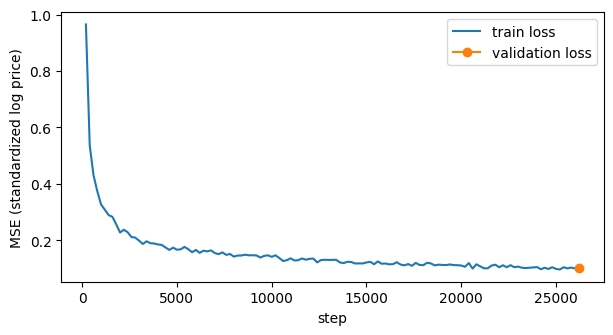

In [8]:
log = pd.DataFrame(trainer.state.log_history)

ax = log.dropna(subset=["loss"]).plot(x="step", y="loss", label="train loss", figsize=(7, 3.5))
log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", label="validation loss", marker="o", ax=ax)
ax.set_ylabel("MSE (standardized log price)")
plt.show()

## Results

Predictions are converted back to prices (undo the standardization, then `expm1`).

In [9]:
def evaluate(y_true, y_pred):
    return {
        "MAE (bn VND)": mean_absolute_error(y_true, y_pred) / 1e9,
        "RMSE (bn VND)": root_mean_squared_error(y_true, y_pred) / 1e9,
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


# log1p(price) predicted by BamiBERT
bamibert_val = trainer.predict(val_ds).predictions.squeeze(-1) * y_std + y_mean
bamibert_test = trainer.predict(test_ds).predictions.squeeze(-1) * y_std + y_mean

table = pd.DataFrame({"BamiBERT (text only)": evaluate(test["price"], np.expm1(bamibert_test))}).T

os.makedirs("../reports/metrics", exist_ok=True)
table.to_csv("../reports/metrics/08_bamibert.csv")

notebook_06 = pd.read_csv("../reports/metrics/06_text_tfidf.csv", index_col=0)
pd.concat([notebook_06, table]).style.format("{:,.3f}")

,MAE (bn VND),RMSE (bn VND),R2,MAPE (%)
Ridge: text + structured,4.935,21.606,0.632,28.090
LightGBM + text prediction,4.223,17.317,0.764,25.050
BamiBERT (text only),4.355,17.353,0.763,26.856


## Save predictions

Validation and test predictions (`log1p(price)`) for the ensemble in notebook 10.

In [10]:
predictions = pd.concat([
    pd.DataFrame({"split": "val", "BamiBERT": bamibert_val}, index=val.index),
    pd.DataFrame({"split": "test", "BamiBERT": bamibert_test}, index=test.index),
])

os.makedirs("../reports/predictions", exist_ok=True)
predictions.to_parquet("../reports/predictions/08_bamibert.parquet")
predictions.head()

,split,BamiBERT
1677900,val,22.069439
1677901,val,22.354562
1677902,val,21.126019
1677903,val,25.168051
1677904,val,22.174264
